# ENDTERM PROJECT — ISS Real-Time Monitoring, Time-Series Analysis and Stream Intelligence

This notebook is the defense-friendly implementation of the complete project. It uses the supplied `processed_iss_data.csv` dataset and covers live visualization, time-series analysis, anomaly detection, real-time machine learning, distributed stream-processing concepts and operational metrics.

In [1]:
import json, time, queue, threading, joblib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import clear_output, display
from sklearn.ensemble import IsolationForest, RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix

base = Path.cwd()
data_path = base / "data" / "processed_iss_data.csv"
df = pd.read_csv(data_path, parse_dates=["timestamp"]).sort_values("timestamp").reset_index(drop=True)
print(df.shape)
display(df.head())

(8640, 17)


,timestamp,latitude,longitude,altitude_km,speed_kmph,Hemisphere,region,is_iqr_outlier,speed_mps,rolling_avg_altitude,rolling_avg_speed,rolling_altitude_std,minimum_altitude,maximum_altitude,altitude_rate,anomaly,event_count
0,2025-06-07 00:00:00+00:00,-10.459060,133.051468,368.18,27687.89,Southern,Pacific Ocean,False,7691.080556,368.1800,27687.8900,0.000000,368.18,368.18,0.000,False,0
1,2025-06-07 00:00:10+00:00,-9.948827,133.427909,368.06,27688.23,Southern,Pacific Ocean,False,7691.175000,368.1200,27688.0600,0.060000,368.06,368.18,-0.012,False,0
2,2025-06-07 00:00:20+00:00,-9.438046,133.803068,367.94,27688.57,Southern,Pacific Ocean,False,7691.269444,368.0600,27688.2300,0.097980,367.94,368.18,-0.012,False,0
3,2025-06-07 00:00:30+00:00,-8.926744,134.177013,367.83,27688.90,Southern,Pacific Ocean,False,7691.361111,368.0025,27688.3975,0.130839,367.83,368.18,-0.011,False,0
4,2025-06-07 00:00:40+00:00,-8.414952,134.549815,367.72,27689.23,Southern,Pacific Ocean,False,7691.452778,367.9460,27688.5640,0.162678,367.72,368.18,-0.011,False,0


## 1. Dataset and stream properties

The dataset contains one full day of ISS telemetry sampled every 10 seconds. We verify ordering, missing values and the supplied anomaly label before modelling.

In [2]:
print("Start:", df.timestamp.min())
print("End:", df.timestamp.max())
print("Sampling interval:", df.timestamp.diff().dropna().mode().iloc[0])
print("Missing values:", int(df.isna().sum().sum()))
print("Events:", len(df))
print("Ground-truth anomalies:", int(df.anomaly.sum()), f"({df.anomaly.mean():.2%})")

Start: 2025-06-07 00:00:00+00:00
End: 2025-06-07 23:59:50+00:00
Sampling interval: 0 days 00:00:10
Missing values: 0
Events: 8640
Ground-truth anomalies: 457 (5.29%)


## 2. Time-series analysis

We resample the 10-second stream to one-minute means, add trailing 5-minute trends, and estimate the strongest repeating altitude period in the 60–120 minute band using an FFT. These operations use timestamps and temporal windows as required.

Dominant repeating altitude period in 60–120 min band: 102.9 minutes


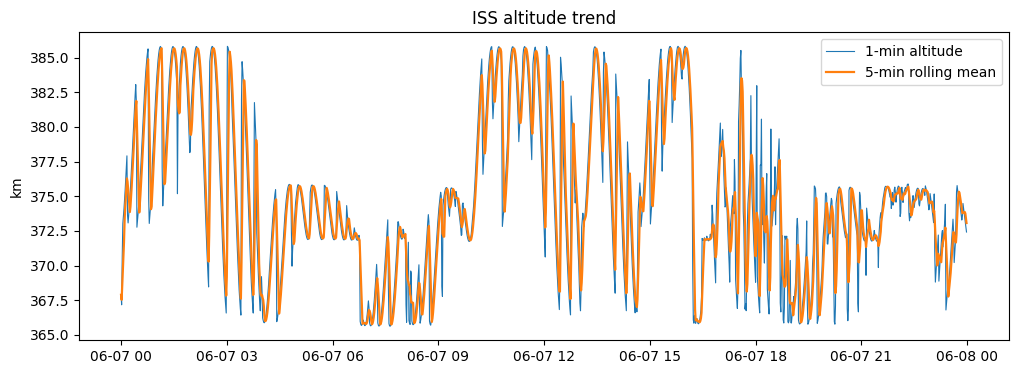

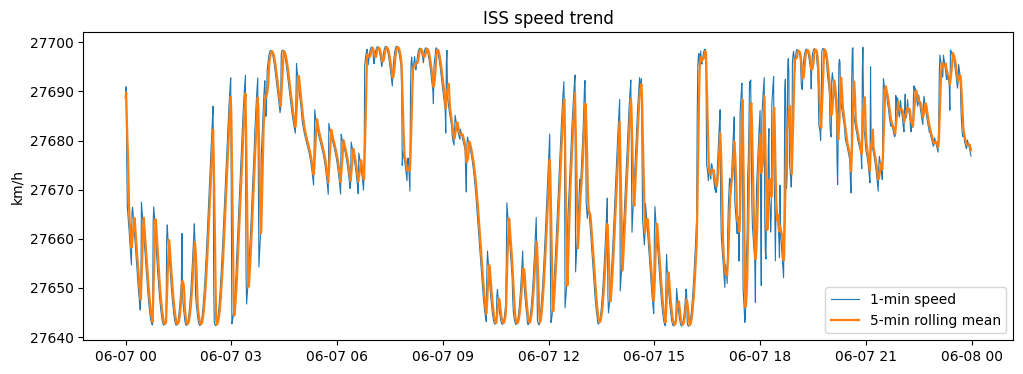

In [3]:
ts = df.set_index("timestamp")
one_min = ts[["altitude_km", "speed_kmph"]].resample("1min").mean()
one_min["altitude_5min_mean"] = one_min.altitude_km.rolling(5, min_periods=1).mean()
one_min["speed_5min_mean"] = one_min.speed_kmph.rolling(5, min_periods=1).mean()

x = one_min.altitude_km.to_numpy() - one_min.altitude_km.mean()
freq = np.fft.rfftfreq(len(x), d=1.0)
power = np.abs(np.fft.rfft(x))**2
periods = np.full_like(freq, np.inf, dtype=float)
periods[freq > 0] = 1 / freq[freq > 0]
band = (periods >= 60) & (periods <= 120)
dominant_period = periods[band][np.argmax(power[band])]
print(f"Dominant repeating altitude period in 60–120 min band: {dominant_period:.1f} minutes")

fig, ax = plt.subplots(figsize=(12,4))
ax.plot(one_min.index, one_min.altitude_km, label="1-min altitude", linewidth=.8)
ax.plot(one_min.index, one_min.altitude_5min_mean, label="5-min rolling mean", linewidth=1.6)
ax.set_title("ISS altitude trend")
ax.set_ylabel("km")
ax.legend(); plt.show()

fig, ax = plt.subplots(figsize=(12,4))
ax.plot(one_min.index, one_min.speed_kmph, label="1-min speed", linewidth=.8)
ax.plot(one_min.index, one_min.speed_5min_mean, label="5-min rolling mean", linewidth=1.6)
ax.set_title("ISS speed trend")
ax.set_ylabel("km/h")
ax.legend(); plt.show()

## 3. Anomaly detection

Isolation Forest is trained without anomaly labels on the first 70% of the chronological stream. It uses only current `altitude_rate` and `speed_kmph`; the last 30% is evaluated against the supplied `anomaly` label.

Precision: 0.7183
Recall: 0.51
F1: 0.5965
Confusion matrix: [[2352   40]
 [  98  102]]


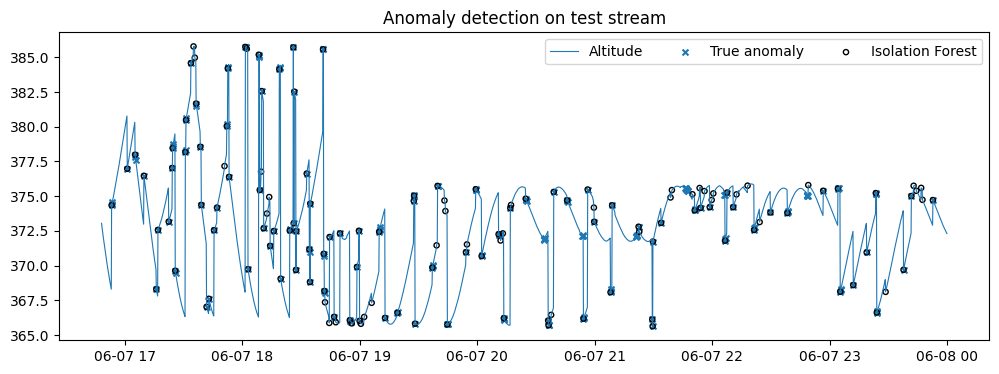

In [4]:
anomaly_features = ["altitude_rate", "speed_kmph"]
split = int(len(df) * 0.70)
train_a, test_a = df.iloc[:split], df.iloc[split:]

isolation_model = make_pipeline(
    StandardScaler(),
    IsolationForest(n_estimators=300, contamination=0.03, random_state=42)
)
isolation_model.fit(train_a[anomaly_features])
anomaly_pred = (isolation_model.predict(test_a[anomaly_features]) == -1).astype(int)
y_an = test_a.anomaly.astype(int)

print("Precision:", round(precision_score(y_an, anomaly_pred), 4))
print("Recall:", round(recall_score(y_an, anomaly_pred), 4))
print("F1:", round(f1_score(y_an, anomaly_pred), 4))
print("Confusion matrix:", confusion_matrix(y_an, anomaly_pred))

fig, ax = plt.subplots(figsize=(12,4))
ax.plot(test_a.timestamp, test_a.altitude_km, linewidth=.8, label="Altitude")
ax.scatter(test_a.loc[y_an.astype(bool), "timestamp"], test_a.loc[y_an.astype(bool), "altitude_km"], marker="x", s=18, label="True anomaly")
mask = anomaly_pred.astype(bool)
ax.scatter(test_a.loc[mask, "timestamp"], test_a.loc[mask, "altitude_km"], facecolors="none", edgecolors="black", s=14, label="Isolation Forest")
ax.legend(ncol=3); ax.set_title("Anomaly detection on test stream"); plt.show()

## 4. Real-time machine learning

Prediction task: at current event **t**, predict whether altitude at **t+1** will be higher. The target uses the next event only during training/evaluation; the features available to the model are all known at time t. A chronological split avoids future-to-past leakage.

Accuracy: 0.9595
F1: 0.9639
ROC-AUC: 0.9748
Confusion matrix: [[1085   53]
 [  52 1402]]


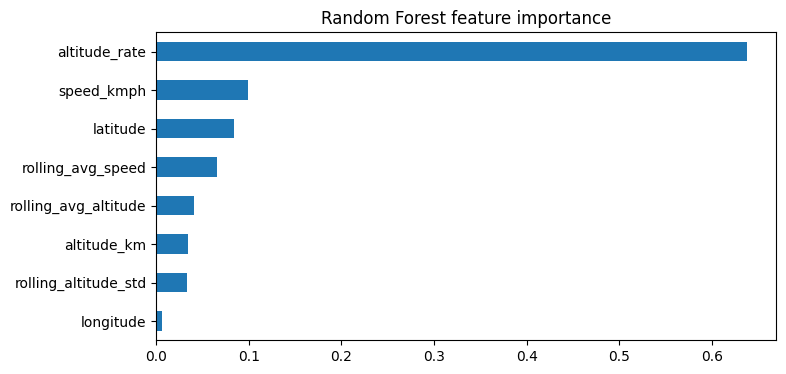

In [5]:
ml_features = [
    "latitude", "longitude", "altitude_km", "speed_kmph",
    "rolling_avg_altitude", "rolling_avg_speed",
    "rolling_altitude_std", "altitude_rate"
]
ml = df.copy()
next_altitude = ml.altitude_km.shift(-1)
ml["target_up"] = (next_altitude > ml.altitude_km).astype(int)
ml = ml.iloc[:-1].copy()
split_ml = int(len(ml) * 0.70)
train_ml, test_ml = ml.iloc[:split_ml], ml.iloc[split_ml:]

rf = RandomForestClassifier(
    n_estimators=250, max_depth=12, min_samples_leaf=2,
    class_weight="balanced", n_jobs=-1, random_state=42
)
rf.fit(train_ml[ml_features], train_ml.target_up)
pred = rf.predict(test_ml[ml_features])
prob = rf.predict_proba(test_ml[ml_features])[:,1]

print("Accuracy:", round(accuracy_score(test_ml.target_up, pred), 4))
print("F1:", round(f1_score(test_ml.target_up, pred), 4))
print("ROC-AUC:", round(roc_auc_score(test_ml.target_up, prob), 4))
print("Confusion matrix:", confusion_matrix(test_ml.target_up, pred))

importance = pd.Series(rf.feature_importances_, index=ml_features).sort_values()
importance.plot.barh(figsize=(8,4), title="Random Forest feature importance")
plt.show()

## 5. Distributed stream-processing simulation

One producer partitions events round-robin into three FIFO queues. Three independent workers consume their partitions. Each worker applies the ML and anomaly models, then results are aggregated. We measure event count, throughput, end-to-end latency and backlog.

In [6]:
def distributed_demo(data, workers=3, batch_size=64):
    queues = [queue.Queue() for _ in range(workers)]
    stop = object(); results=[]; lat=[]; lock=threading.Lock(); max_backlog=0

    def process_batch(worker_id, batch):
        rows = [b[2] for b in batch]
        x = pd.DataFrame(rows)
        p = rf.predict_proba(x[ml_features])[:,1]
        a = isolation_model.predict(x[anomaly_features]) == -1
        end = time.perf_counter()
        local=[]; local_lat=[]
        for item, pp, aa in zip(batch, p, a):
            seq, queued, row = item
            ms=(end-queued)*1000
            local_lat.append(ms)
            local.append((seq, worker_id, pp, bool(aa), ms))
        with lock:
            results.extend(local); lat.extend(local_lat)

    def worker(wid):
        q=queues[wid]
        while True:
            first=q.get()
            if first is stop:
                q.task_done(); break
            batch=[first]; saw_stop=False
            while len(batch)<batch_size:
                try: nxt=q.get_nowait()
                except queue.Empty: break
                if nxt is stop:
                    q.task_done(); saw_stop=True; break
                batch.append(nxt)
            process_batch(wid,batch)
            for _ in batch: q.task_done()
            if saw_stop: break

    threads=[threading.Thread(target=worker,args=(i,),daemon=True) for i in range(workers)]
    for t in threads: t.start()
    start=time.perf_counter()
    for seq,row in data.iterrows():
        queues[seq % workers].put((int(seq), time.perf_counter(), row.to_dict()))
        max_backlog=max(max_backlog, sum(q.qsize() for q in queues))
    for q in queues: q.put(stop)
    for q in queues: q.join()
    for t in threads: t.join()
    elapsed=time.perf_counter()-start
    metrics={
        "event_count": len(results),
        "throughput_events_per_sec": len(results)/elapsed,
        "mean_latency_ms": float(np.mean(lat)),
        "p95_latency_ms": float(np.percentile(lat,95)),
        "max_backlog": max_backlog,
        "worker_count": workers,
    }
    return metrics

stream_metrics = distributed_demo(df)
stream_metrics

{'event_count': 8640,
 'throughput_events_per_sec': 828.0654458868441,
 'mean_latency_ms': 5351.619626703125,
 'p95_latency_ms': 9672.56618085003,
 'max_backlog': 8448,
 'worker_count': 3}

## 6. Continuously updated visualization demo

This compact notebook replay updates two charts from incoming batches. The full `dashboard.py` provides the Streamlit version used for presentation/demo.

In [7]:
# Live visualization is intentionally skipped in the saved executed copy.
print("Run the live replay cell from ISS_Endterm_Project.ipynb during defence.")

Run the live replay cell from ISS_Endterm_Project.ipynb during defence.


## 7. Final requirement checklist

- Two continuously updated visualizations: altitude + speed.
- Timestamp-based resampling, rolling trends and repeating-period analysis.
- Isolation Forest anomaly detector with precision/recall/F1 evaluation.
- Real-time Random Forest classifier with F1 and ROC-AUC.
- Prediction-time-safe features and chronological split.
- Producer + three partitions + three workers + analytics stage.
- Operational event count, throughput, latency and backlog metrics.
- Reproducible Python code, dataset, dashboard and trained-model scripts in the project folder.